In [6]:
import pandas as pd
tel_data = pd.read_csv(r"C:\Users\Admin\Desktop\CS\ML Class\CSV files\telescope_data.csv")
tel_data.head()

,Unnamed: 0,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


In [7]:
tel_data.columns = [cols.lower() for cols in tel_data.columns]
tel_data.head()

,unnamed: 0,flength,fwidth,fsize,fconc,fconc1,fasym,fm3long,fm3trans,falpha,fdist,class
0,0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


In [8]:
tel_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 19020 entries, 0 to 19019
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   unnamed: 0  19020 non-null  int64  
 1   flength     19020 non-null  float64
 2   fwidth      19020 non-null  float64
 3   fsize       19020 non-null  float64
 4   fconc       19020 non-null  float64
 5   fconc1      19020 non-null  float64
 6   fasym       19020 non-null  float64
 7   fm3long     19020 non-null  float64
 8   fm3trans    19020 non-null  float64
 9   falpha      19020 non-null  float64
 10  fdist       19020 non-null  float64
 11  class       19020 non-null  str    
dtypes: float64(10), int64(1), str(1)
memory usage: 1.7 MB


In [9]:
tel_data.describe()

,unnamed: 0,flength,fwidth,fsize,fconc,fconc1,fasym,fm3long,fm3trans,falpha,fdist
count,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000
mean,9509.500000,53.250154,22.180966,2.825017,0.380327,0.214657,-4.331745,10.545545,0.249726,27.645707,193.818026
std,5490.745396,42.364855,18.346056,0.472599,0.182813,0.110511,59.206062,51.000118,20.827439,26.103621,74.731787
min,0.000000,4.283500,0.000000,1.941300,0.013100,0.000300,-457.916100,-331.780000,-205.894700,0.000000,1.282600
25%,4754.750000,24.336000,11.863800,2.477100,0.235800,0.128475,-20.586550,-12.842775,-10.849375,5.547925,142.492250
50%,9509.500000,37.147700,17.139900,2.739600,0.354150,0.196500,4.013050,15.314100,0.666200,17.679500,191.851450
75%,14264.250000,70.122175,24.739475,3.101600,0.503700,0.285225,24.063700,35.837800,10.946425,45.883550,240.563825
max,19019.000000,334.177000,256.382000,5.323300,0.893000,0.675200,575.240700,238.321000,179.851000,90.000000,495.561000


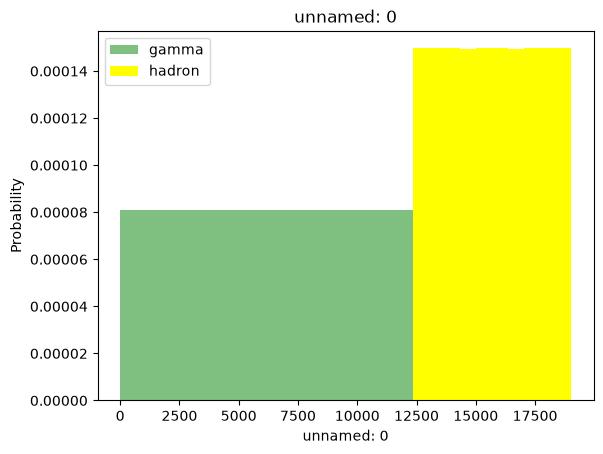

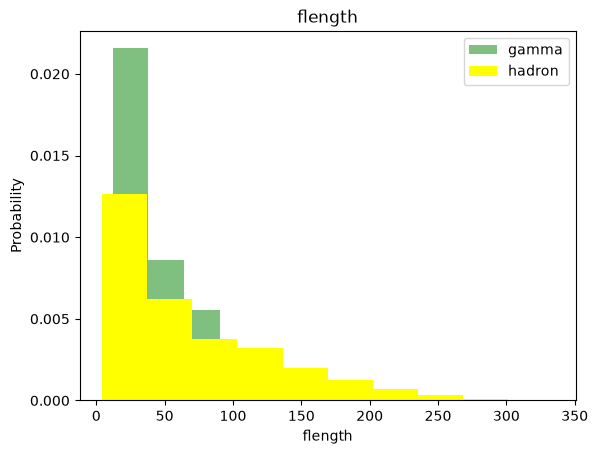

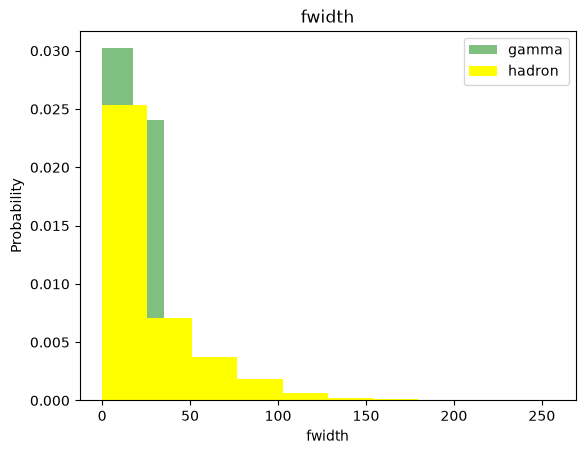

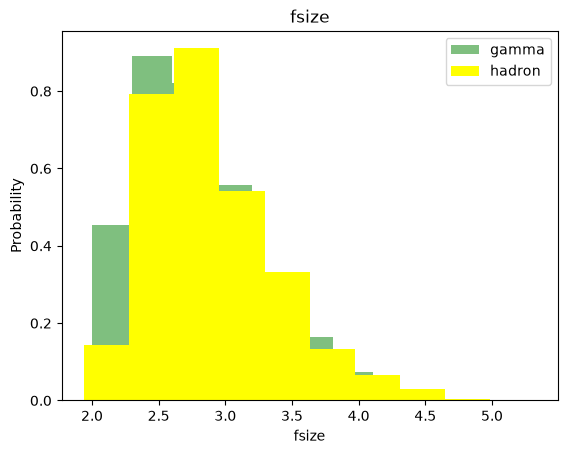

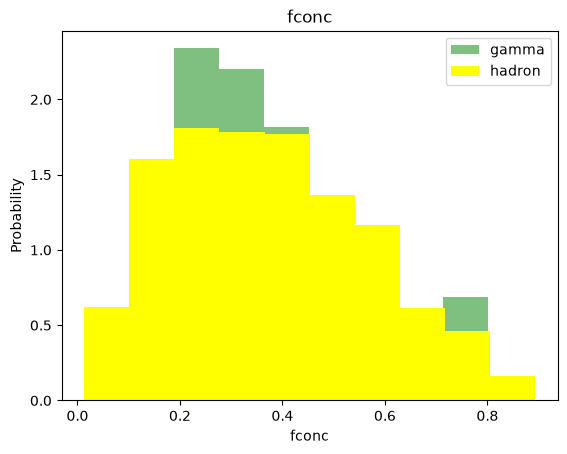

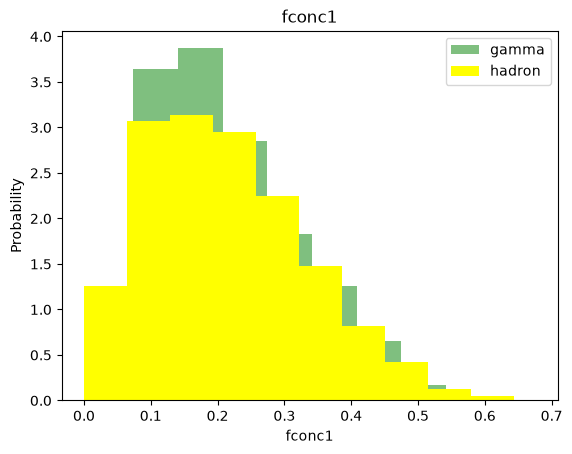

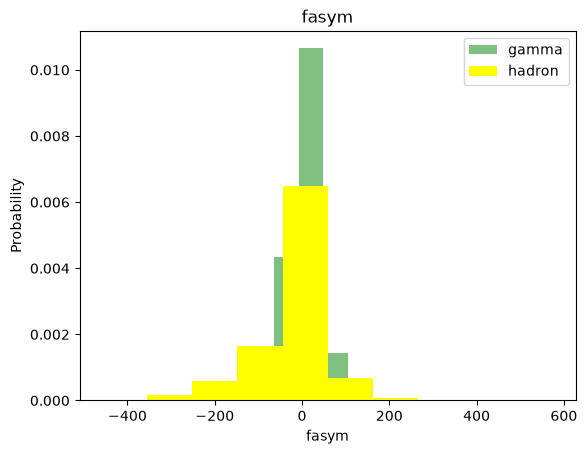

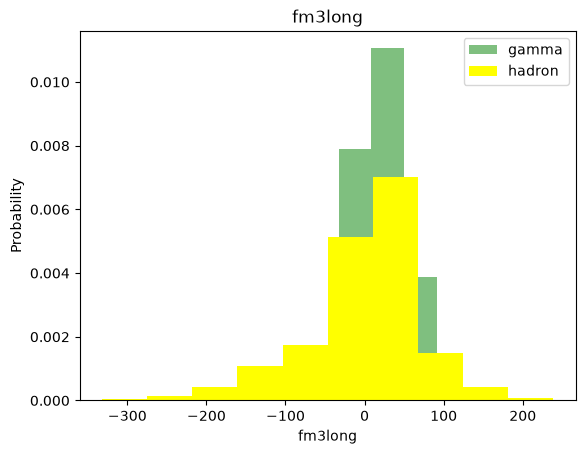

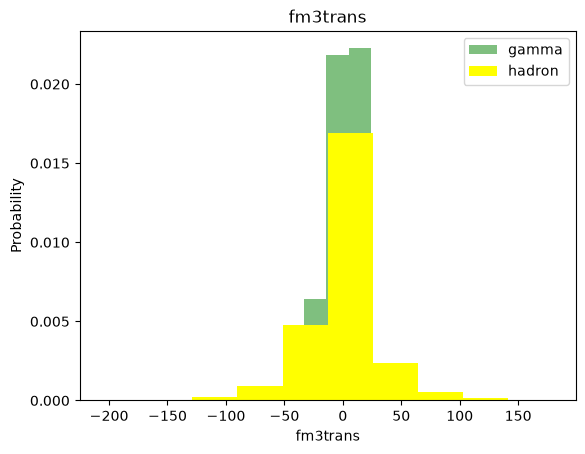

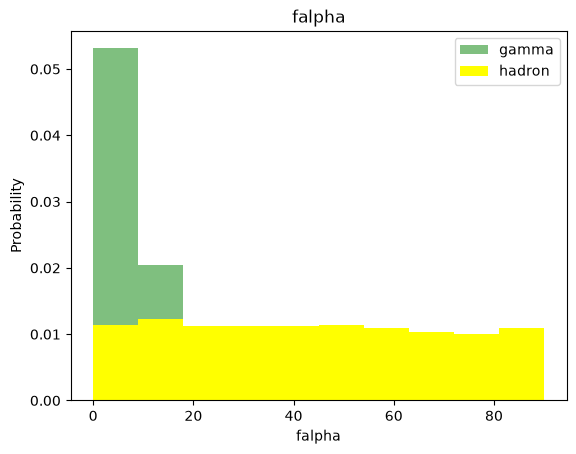

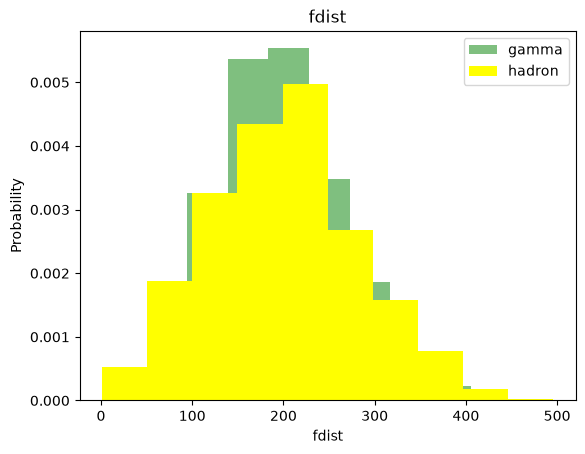

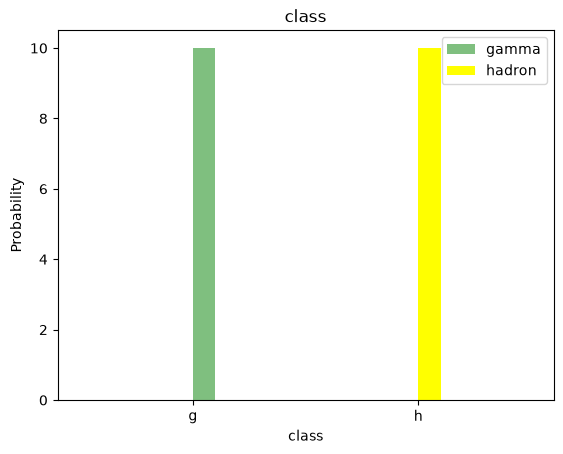

In [13]:
import matplotlib.pyplot as plt
for label in (tel_data.columns):
    plt.hist(tel_data[tel_data['class']=='g'][label],color="green",label='gamma',alpha=0.5,density=True)
    plt.hist(tel_data[tel_data['class']=='h'][label],color="yellow",label='hadron',alpha=1,density=True)
    plt.title(label)
    plt.ylabel("Probability")
    plt.xlabel(label)
    plt.legend()
    plt.show();

In [14]:
from sklearn.model_selection import train_test_split
ds_train,ds_test= train_test_split(tel_data,test_size=0.2)

In [15]:
print(len(ds_train))
print(len(ds_test))

15216
3804


In [16]:
print(len(ds_train[ds_train['class']=='g']))
print(len(ds_train[ds_train['class']=='h']))

9861
5355


In [17]:
from imblearn.over_sampling import RandomOverSampler
r_ram = RandomOverSampler()
in_ds_train = ds_train.drop(columns=['class'])
out_ds_train =ds_train['class']

In [18]:
print(in_ds_train)

       unnamed: 0   flength   fwidth   fsize   fconc  fconc1     fasym  \
48             48   63.2886  26.4270  3.4434  0.2342  0.1273  -27.3566   
1928         1928   35.9040  26.8518  2.8794  0.1954  0.1076   31.3797   
8375         8375   95.3993  28.8213  3.4232  0.2638  0.1481   21.5785   
153           153   52.8479  21.5505  2.9462  0.3667  0.2054  -53.2694   
6227         6227  100.7990  24.4560  3.0400  0.1778  0.0907  -65.5120   
...           ...       ...      ...     ...     ...     ...       ...   
15372       15372   13.0870  10.5001  2.1538  0.7789  0.4947   13.0447   
10025       10025   22.3493  11.4690  2.5922  0.5396  0.3261   -6.4752   
16653       16653   19.3584   7.7947  2.4871  0.7655  0.4967   -2.2146   
12778       12778  126.4411  97.2485  4.0199  0.0658  0.0397 -104.2694   
5986         5986  100.6070  27.9874  3.3503  0.1567  0.0828  -23.4589   

       fm3long  fm3trans   falpha     fdist  
48     54.6506   19.7834   0.9753  302.8970  
1928   33.4534   15

In [19]:
print(out_ds_train)

48       g
1928     g
8375     g
153      g
6227     g
        ..
15372    h
10025    g
16653    h
12778    h
5986     g
Name: class, Length: 15216, dtype: str


In [20]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
in_ds_train= scaler.fit_transform(in_ds_train)
print(in_ds_train)

[[-1.72639102  0.23986     0.23563827 ...  0.94307737 -1.02180352
   1.4612861 ]
 [-1.38407814 -0.40775898  0.25914374 ...  0.72247946  2.28891747
  -0.89940939]
 [-0.21019987  0.99924663  0.36812214 ...  1.07931585 -1.02443463
   2.11521034]
 ...
 [ 1.29706931 -0.79904622 -0.79534329 ... -0.44894712  0.14523647
   0.16897574]
 [ 0.59150419  1.73335481  4.15440624 ...  0.29026798  2.31228057
   1.88212137]
 [-0.64519214  1.12240363  0.32197993 ... -0.63485468 -1.0114738
   1.58595199]]


In [21]:
in_ds_train,out_ds_train = r_ram.fit_resample(in_ds_train,out_ds_train)
print(len(out_ds_train))
print(sum(out_ds_train == 'g'))
print(sum(out_ds_train == 'h'))

19722
9861
9861


In [22]:
in_ds_test = ds_test.drop(columns = ['class'])
out_ds_test=ds_test['class']
in_ds_test= scaler.fit_transform(in_ds_test)

In [23]:
in_ds_test

array([[-1.3567997 , -0.24825905, -0.51652165, ...,  0.25250365,
        -1.03031082,  0.49325396],
       [-1.5730624 , -0.50124839, -0.30039572, ..., -0.87689982,
        -0.58137001,  0.16527438],
       [ 0.10306467, -0.5480468 , -0.40267512, ..., -0.53803271,
        -0.83217894, -0.97156135],
       ...,
       [ 1.07497038, -0.57534412, -0.43059809, ...,  0.275521  ,
         1.38779547, -0.04079161],
       [-0.02074846, -0.63671797, -0.63062076, ..., -0.30954534,
         0.36595141,  0.57528576],
       [ 0.99127343, -0.18921914, -0.60544524, ...,  0.16252888,
        -0.15848244, -0.36944763]], shape=(3804, 11))

In [24]:
print(len(in_ds_test))

3804


In [25]:
from sklearn.neighbors import KNeighborsClassifier
Knn_model = KNeighborsClassifier(n_neighbors = 2)
Knn_model.fit(in_ds_train,out_ds_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",2
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['g','h']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [28]:
out_pred = Knn_model.predict(in_ds_test)

In [29]:
out_pred

array(['g', 'g', 'g', ..., 'h', 'g', 'h'], shape=(3804,), dtype=object)

In [30]:
from sklearn.metrics import accuracy_score
accuracy_info =accuracy_score(out_ds_test,out_pred)
accuracy_info

0.9647739221871714